# Notebook 01: Support Vector Machines, Street Margins ($\frac{2}{\|\mathbf{w}\|_2}$) & 3D RBF Kernel Lifting

In this notebook we explore:
1. **Soft-Margin vs. Hard-Margin Street Width:** Comparing a Soft-Margin SVM ($C = 0.35$) that maintains a wide street $\gamma = \frac{2}{\|\mathbf{w}\|_2}$ against a Harder-Margin SVM ($C = 45.0$) that narrows the street to avoid margin violations.
2. **Support Vectors:** Highlighting the exact data points where $\alpha_i > 0$ ($y^{(i)}(\mathbf{w}^\top \mathbf{x}^{(i)} + b) \le 1$) that physically support the margin curbs.
3. **The RBF Kernel Trick in 3D:** Lifting 2D concentric rings into 3D via the Radial Basis Function $z = \exp(-\gamma\|\mathbf{x}\|_2^2)$ so that a flat linear hyperplane slices cleanly between the two classes!

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Ensure src package is importable
repo_root = Path.cwd()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.classifiers_engine import KernelSVMScratch, LinearSVMScratch
from src.plot_theme import (
    AMBER,
    BG_CANVAS,
    CMAP_DECISION,
    CMAP_SURFACE,
    CORAL,
    CYAN,
    EMERALD,
    PURPLE,
    SLATE_BLUE,
    TEXT_MUTED,
    apply_github_dark_style,
    save_fig,
    style_3d_axis,
)

apply_github_dark_style()

## 1. Soft-Margin ($C = 0.35$) vs. Harder-Margin ($C = 45.0$) Linear SVM

In [2]:
rng = np.random.default_rng(42)
m_half = 55
X_neg = rng.normal(loc=[-1.35, -1.15], scale=0.62, size=(m_half, 2))
X_pos = rng.normal(loc=[1.35, 1.15], scale=0.62, size=(m_half, 2))
# Add two borderline interior points near the boundary to highlight C sensitivity
X_neg = np.vstack([X_neg, [[0.25, -0.15], [-0.10, 0.35]]])
X_pos = np.vstack([X_pos, [[-0.20, 0.10], [0.15, -0.25]]])

X_lin = np.vstack([X_neg, X_pos])
y_lin = np.concatenate([np.zeros(len(X_neg)), np.ones(len(X_pos))])

svm_soft = LinearSVMScratch(C=0.35, learning_rate=0.04, epochs=1200).fit(X_lin, y_lin)
svm_hard = LinearSVMScratch(C=45.0, learning_rate=0.012, epochs=2000).fit(X_lin, y_lin)

print(f"Soft-Margin (C = 0.35) | Street Width 2/||w||_2 = {svm_soft.geometric_margin:.4f} | Support Vectors: {len(svm_soft.support_vector_indices_)}")
print(f"Hard-Margin (C = 45.0) | Street Width 2/||w||_2 = {svm_hard.geometric_margin:.4f} | Support Vectors: {len(svm_hard.support_vector_indices_)}")

Soft-Margin (C = 0.35) | Street Width 2/||w||_2 = 4.5950 | Support Vectors: 101
Hard-Margin (C = 45.0) | Street Width 2/||w||_2 = 1.8503 | Support Vectors: 13


## 2. Dual RBF Kernel SVM & 3D Gaussian Kernel Lifting on Concentric Rings

In [3]:
n_ring = 80
theta_0 = rng.uniform(0, 2 * np.pi, n_ring)
r_0 = rng.normal(0.48, 0.11, n_ring)
X_ring_0 = np.column_stack([r_0 * np.cos(theta_0), r_0 * np.sin(theta_0)])

theta_1 = rng.uniform(0, 2 * np.pi, n_ring)
r_1 = rng.normal(1.55, 0.14, n_ring)
X_ring_1 = np.column_stack([r_1 * np.cos(theta_1), r_1 * np.sin(theta_1)])

X_rings = np.vstack([X_ring_0, X_ring_1])
y_rings = np.concatenate([np.zeros(n_ring), np.ones(n_ring)])

gamma_rbf = 0.9
ksvm_rbf = KernelSVMScratch(C=10.0, kernel="rbf", gamma=gamma_rbf, epochs=600).fit(X_rings, y_rings)
print(
    f"RBF Kernel SVM (gamma={gamma_rbf}) | Accuracy: {np.mean(ksvm_rbf.predict(X_rings) == y_rings)*100:.2f}% | "
    f"Dual Support Vectors: {len(ksvm_rbf.support_vector_indices_)}"
)

RBF Kernel SVM (gamma=0.9) | Accuracy: 100.00% | Dual Support Vectors: 85


## 3. Three-Panel Diagnostic Visualization (`01_svm_margins_and_rbf_kernel.png`)

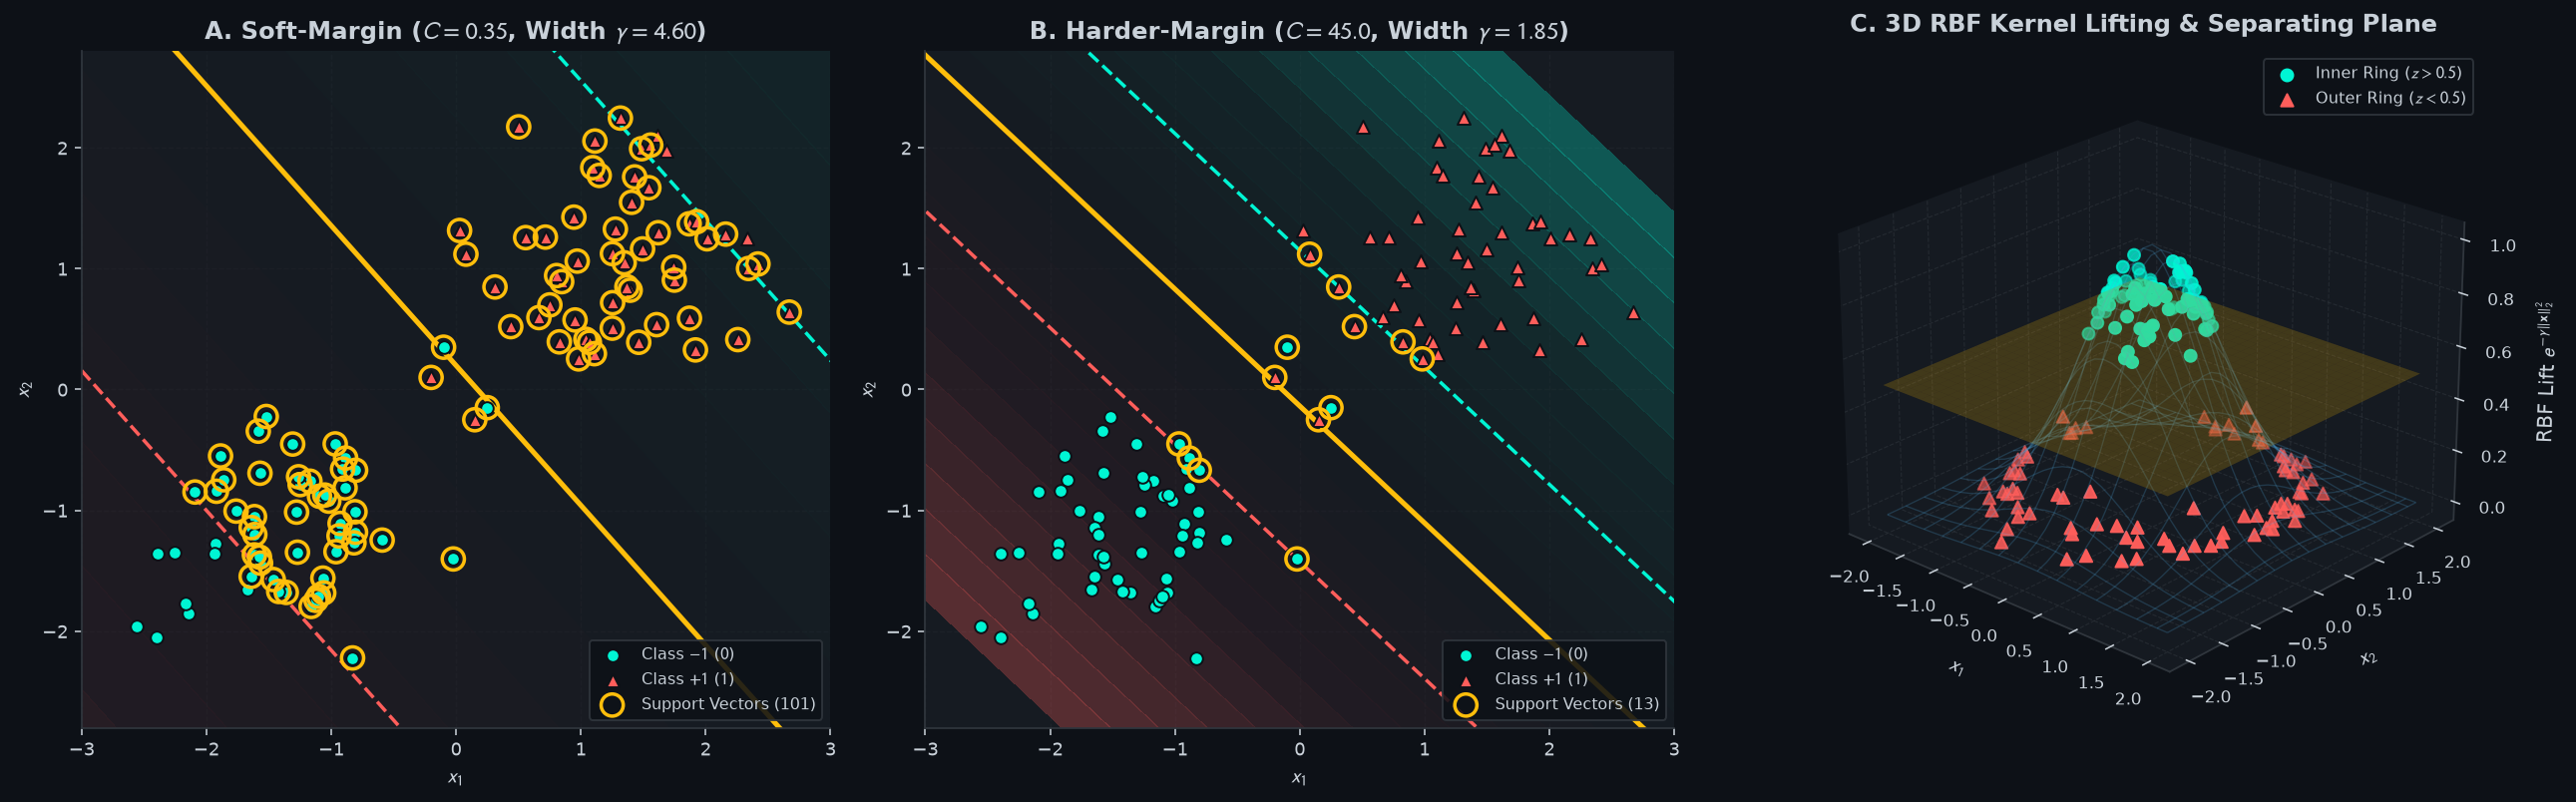

In [4]:
fig = plt.figure(figsize=(18.5, 5.8))
ax1 = fig.add_subplot(1, 3, 1)
ax2 = fig.add_subplot(1, 3, 2)
ax3 = fig.add_subplot(1, 3, 3, projection="3d")

x1_grid = np.linspace(-3.1, 3.1, 200)
x2_grid = np.linspace(-3.1, 3.1, 200)
XX1, XX2 = np.meshgrid(x1_grid, x2_grid)
grid_pts = np.c_[XX1.ravel(), XX2.ravel()]

for ax, model, title_str in [
    (ax1, svm_soft, f"A. Soft-Margin ($C=0.35$, Width $\\gamma={svm_soft.geometric_margin:.2f}$)"),
    (ax2, svm_hard, f"B. Harder-Margin ($C=45.0$, Width $\\gamma={svm_hard.geometric_margin:.2f}$)"),
]:
    Z_dec = model.decision_function(grid_pts).reshape(XX1.shape)
    ax.contourf(XX1, XX2, Z_dec, levels=np.linspace(-3.5, 3.5, 25), cmap=CMAP_DECISION, alpha=0.30)
    # Plot decision boundary (0) and margin gutters (-1, +1)
    ax.contour(XX1, XX2, Z_dec, levels=[-1.0, 0.0, 1.0], colors=[CORAL, AMBER, CYAN], linestyles=["--", "-", "--"], linewidths=[1.8, 2.6, 1.8])

    mask0 = y_lin == 0
    mask1 = y_lin == 1
    ax.scatter(X_lin[mask0, 0], X_lin[mask0, 1], c=CYAN, s=42, edgecolors=BG_CANVAS, label="Class $-1$ ($0$)", zorder=4)
    ax.scatter(X_lin[mask1, 0], X_lin[mask1, 1], c=CORAL, marker="^", s=45, edgecolors=BG_CANVAS, label="Class $+1$ ($1$)", zorder=4)

    sv_idx = model.support_vector_indices_
    ax.scatter(
        X_lin[sv_idx, 0],
        X_lin[sv_idx, 1],
        s=130,
        facecolors="none",
        edgecolors=AMBER,
        linewidths=1.8,
        label=f"Support Vectors ({len(sv_idx)})",
        zorder=5,
    )
    ax.set_xlim(-3.0, 3.0)
    ax.set_ylim(-2.8, 2.8)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_title(title_str)
    ax.legend(loc="lower right", fontsize=8.4)

# Panel C: 3D RBF Kernel Lifting phi_3(x) = exp(-gamma * ||x||_2^2)
style_3d_axis(ax3)
z_lift_all = np.exp(-gamma_rbf * np.sum(X_rings ** 2, axis=1))
r0_mask = y_rings == 0
r1_mask = y_rings == 1

# Plot translucent separating plane z = 0.50 in 3D lifted space
px, py = np.meshgrid(np.linspace(-2.0, 2.0, 30), np.linspace(-2.0, 2.0, 30))
pz = np.full_like(px, 0.50)
ax3.plot_surface(px, py, pz, color=AMBER, alpha=0.26, edgecolor="none")

# Plot translucent RBF bell surface
surf_r = np.exp(-gamma_rbf * (px ** 2 + py ** 2))
ax3.plot_wireframe(px, py, surf_r, color=SLATE_BLUE, alpha=0.22, linewidth=0.7, rstride=2, cstride=2)

ax3.scatter(X_rings[r0_mask, 0], X_rings[r0_mask, 1], z_lift_all[r0_mask], color=CYAN, s=38, label="Inner Ring ($z > 0.5$)")
ax3.scatter(X_rings[r1_mask, 0], X_rings[r1_mask, 1], z_lift_all[r1_mask], color=CORAL, marker="^", s=40, label="Outer Ring ($z < 0.5$)")
ax3.set_xlabel("$x_1$", labelpad=6)
ax3.set_ylabel("$x_2$", labelpad=6)
ax3.set_zlabel("RBF Lift $e^{-\\gamma \\|\\mathbf{x}\\|_2^2}$", labelpad=5)
ax3.set_title("C. 3D RBF Kernel Lifting & Separating Plane", pad=10)
ax3.view_init(elev=24, azim=-48)
ax3.legend(loc="upper right", fontsize=8.4)

fig.tight_layout()
assets_dir = Path("assets")
assets_dir.mkdir(parents=True, exist_ok=True)
save_fig(fig, assets_dir / "01_svm_margins_and_rbf_kernel.png")
plt.show()